In [976]:
import pandas as pd
import matplotlib.pyplot as plt
import nltk

In [977]:
train = pd.read_csv("/content/train.csv")
test = pd.read_csv("/content/test.csv")

df = pd.concat([train, test], ignore_index=True)
df

,text,label
0,Thanks for your message. I will review the pre...,non-spam
1,"Dear customer, your bank account has been sele...",spam
2,"Dear customer, your email account has been sel...",spam
3,Thanks for your message. I will review the pre...,non-spam
4,Your appointment is confirmed for Friday at 2:...,non-spam
...,...,...
795,"Your loan is pre-approved. Get up to ₹10,000 w...",spam
796,"URGENT: Your account is eligible for a ₹10,000...",spam
797,Don't forget to bring your phone for the the p...,non-spam
798,Please find the presentation attached for tomo...,non-spam


In [978]:
df.head()

,text,label
0,Thanks for your message. I will review the pre...,non-spam
1,"Dear customer, your bank account has been sele...",spam
2,"Dear customer, your email account has been sel...",spam
3,Thanks for your message. I will review the pre...,non-spam
4,Your appointment is confirmed for Friday at 2:...,non-spam


In [979]:
df.tail()

,text,label
795,"Your loan is pre-approved. Get up to ₹10,000 w...",spam
796,"URGENT: Your account is eligible for a ₹10,000...",spam
797,Don't forget to bring your phone for the the p...,non-spam
798,Please find the presentation attached for tomo...,non-spam
799,Your appointment is confirmed for Friday at 11...,non-spam


In [980]:
df.shape

(800, 2)

In [981]:
df.ndim

2

In [982]:
df.columns

Index(['text', 'label'], dtype='object')

In [983]:
df.describe(include=object)

,text,label
count,800,800
unique,800,2
top,Act now to avoid losing your reward. Confirm y...,non-spam
freq,1,402


In [984]:
df.isnull().sum()

,0
text,0
label,0


In [985]:
df.duplicated().sum()

np.int64(0)

In [986]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    800 non-null    object
 1   label   800 non-null    object
dtypes: object(2)
memory usage: 12.6+ KB


In [987]:
df.columns = ["text", "label"]
df

,text,label
0,Thanks for your message. I will review the pre...,non-spam
1,"Dear customer, your bank account has been sele...",spam
2,"Dear customer, your email account has been sel...",spam
3,Thanks for your message. I will review the pre...,non-spam
4,Your appointment is confirmed for Friday at 2:...,non-spam
...,...,...
795,"Your loan is pre-approved. Get up to ₹10,000 w...",spam
796,"URGENT: Your account is eligible for a ₹10,000...",spam
797,Don't forget to bring your phone for the the p...,non-spam
798,Please find the presentation attached for tomo...,non-spam


In [988]:
df.label.unique()

array(['non-spam', 'spam'], dtype=object)

In [989]:
df.label.value_counts()

,count
label,
non-spam,402
spam,398


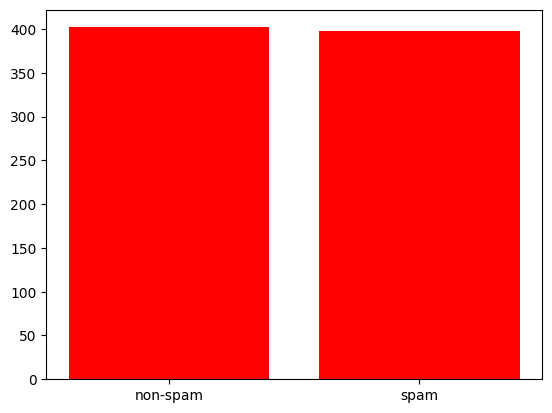

In [990]:
df1 = df.label.value_counts()

# bar chart
plt.bar(df1.index,
        df1.values,
        color="r")
plt.show()

In [991]:
df['label'] = df['label'].map({
    'spam': 0,
    'non-spam': 1
})

In [992]:
tweets = df.text
tweets

,text
0,Thanks for your message. I will review the pre...
1,"Dear customer, your bank account has been sele..."
2,"Dear customer, your email account has been sel..."
3,Thanks for your message. I will review the pre...
4,Your appointment is confirmed for Friday at 2:...
...,...
795,"Your loan is pre-approved. Get up to ₹10,000 w..."
796,"URGENT: Your account is eligible for a ₹10,000..."
797,Don't forget to bring your phone for the the p...
798,Please find the presentation attached for tomo...


In [993]:
tweets = tweets.str.lower()

In [994]:
tweets = tweets.replace(r'[^a-zA-Z0-9\s]', ' ', regex=True)

In [995]:
tweets = tweets.str.replace(r'\s+', ' ', regex=True).str.strip()

In [996]:
from nltk.tokenize import TweetTokenizer

tk = TweetTokenizer()

tweets = tweets.apply(lambda x: tk.tokenize(x)).apply(lambda x: " ".join(x))

In [997]:
tweets = tweets.apply(
    lambda x: " ".join([word for word in tk.tokenize(x) if len(word) >= 3])
)

In [998]:
from nltk.stem import SnowballStemmer

st = SnowballStemmer("english")

tweets = tweets.apply(
    lambda x: [st.stem(i) for i in tk.tokenize(x)]
).apply(lambda x: " ".join(x))

In [999]:
nltk.download('stopwords')

from nltk.corpus import stopwords

stop = set(stopwords.words('english'))

tweets = tweets.apply(
    lambda x: [i for i in tk.tokenize(x) if i not in stop]
).apply(lambda x: " ".join(x))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [1000]:
x = tweets
y = df['label']

In [1001]:
from sklearn.model_selection import train_test_split

xtrain, xtest, ytrain, ytest = train_test_split(
    x, y, test_size=0.30, random_state=42, stratify=y
)

In [1002]:
from sklearn.feature_extraction.text import TfidfVectorizer

vec = TfidfVectorizer()

xtrain = vec.fit_transform(xtrain)
xtest = vec.transform(xtest)

### KNN

In [1003]:
from sklearn.neighbors import KNeighborsClassifier

In [1004]:
knn = KNeighborsClassifier(n_neighbors=7)

In [1005]:
knn.fit(xtrain, ytrain)

KNeighborsClassifier(n_neighbors=7)

In [1006]:
ypred = knn.predict(xtest)

In [1007]:
from sklearn.metrics import accuracy_score

accuracy_score(ytest, ypred)

1.0

In [1008]:
from sklearn.metrics import confusion_matrix

confusion_matrix(ytest, ypred)

array([[119,   0],
       [  0, 121]])

### Naive Bayes

In [1009]:
from sklearn.naive_bayes import MultinomialNB

In [1010]:
nb = MultinomialNB()

In [1011]:
nb.fit(xtrain, ytrain)

MultinomialNB()

In [1012]:
ypred = nb.predict(xtest)

In [1013]:
accuracy_score(ytest, ypred)

1.0

### Decision Tree

In [1014]:
from sklearn.tree import DecisionTreeClassifier

In [1015]:
dt = DecisionTreeClassifier(random_state=42, max_depth = 10)

In [1016]:
dt.fit(xtrain, ytrain)

DecisionTreeClassifier(max_depth=10, random_state=42)

In [1017]:
ypred = dt.predict(xtest)

In [1018]:
accuracy_score(ytest, ypred)

1.0

### Random Forest

In [1019]:
from sklearn.ensemble import RandomForestClassifier

In [1020]:
rf = RandomForestClassifier(n_estimators=100, random_state=42, max_depth = 10)

In [1021]:
rf.fit(xtrain, ytrain)

RandomForestClassifier(max_depth=10, random_state=42)

In [1022]:
ypred = rf.predict(xtest)

In [1023]:
accuracy_score(ytest, ypred)

0.9708333333333333

### XGBoost

In [1024]:
from xgboost import XGBClassifier

In [1025]:
xgb = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss'
)

In [1026]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

y_train_enc = le.fit_transform(ytrain)
y_test_enc = le.transform(ytest)

In [1027]:
xgb.fit(xtrain, y_train_enc)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

In [1028]:
ypred = xgb.predict(xtest)

In [1029]:
accuracy_score(y_test_enc, ypred)

0.9708333333333333

### Logistic Regression

In [1030]:
from sklearn.linear_model import LogisticRegression

In [1031]:
lr = LogisticRegression(max_iter=1000)

In [1032]:
lr.fit(xtrain, ytrain)

LogisticRegression(max_iter=1000)

In [1033]:
ypred = lr.predict(xtest)

In [1034]:
accuracy_score(ytest, ypred)

1.0

In [1035]:
review = ["Congratulations! You have won $1000.Click here to claim your free prize now!"]
vec1 = vec.transform(review)

result=lr.predict(vec1)
result

array([0])

In [1036]:
review = ["Hi, how are you? Are we meeting tomorrow at college?"]

vec1 = vec.transform(review)

result = lr.predict(vec1)
result

array([1])